✓ Libraries loaded.

DOWNLOADING DATASETS
Glass Identification — shape: (214, 11)
  Classes (6): [1, 2, 3, 5, 6, 7]

Wheat Seeds — shape: (210, 8)
  Classes (3): Kama, Rosa, Canadian

Glass   — Train: 149  Test: 65
Seeds   — Train: 147  Test: 63

RUNNING EXPERIMENTS  (4 settings × 2 datasets × Manual + Sklearn)

─────────────────────────────────────────────────────────────────
  DATASET : Glass (6-class)
─────────────────────────────────────────────────────────────────
  [S1] Sigmoid + SGD ... Manual=0.7077  Sklearn=0.7538
  [S2] Tanh + SGD ... Manual=0.6923  Sklearn=0.7692
  [S3] ReLU + Adam ... Manual=0.7385  Sklearn=0.6923
  [S4] ReLU + Adam + L2 ... Manual=0.6923  Sklearn=0.6923

─────────────────────────────────────────────────────────────────
  DATASET : Seeds (3-class)
─────────────────────────────────────────────────────────────────
  [S1] Sigmoid + SGD ... Manual=0.8889  Sklearn=0.8571
  [S2] Tanh + SGD ... Manual=0.8413  Sklearn=0.9048
  [S3] ReLU + Adam ... Manual=0.8889  Sk

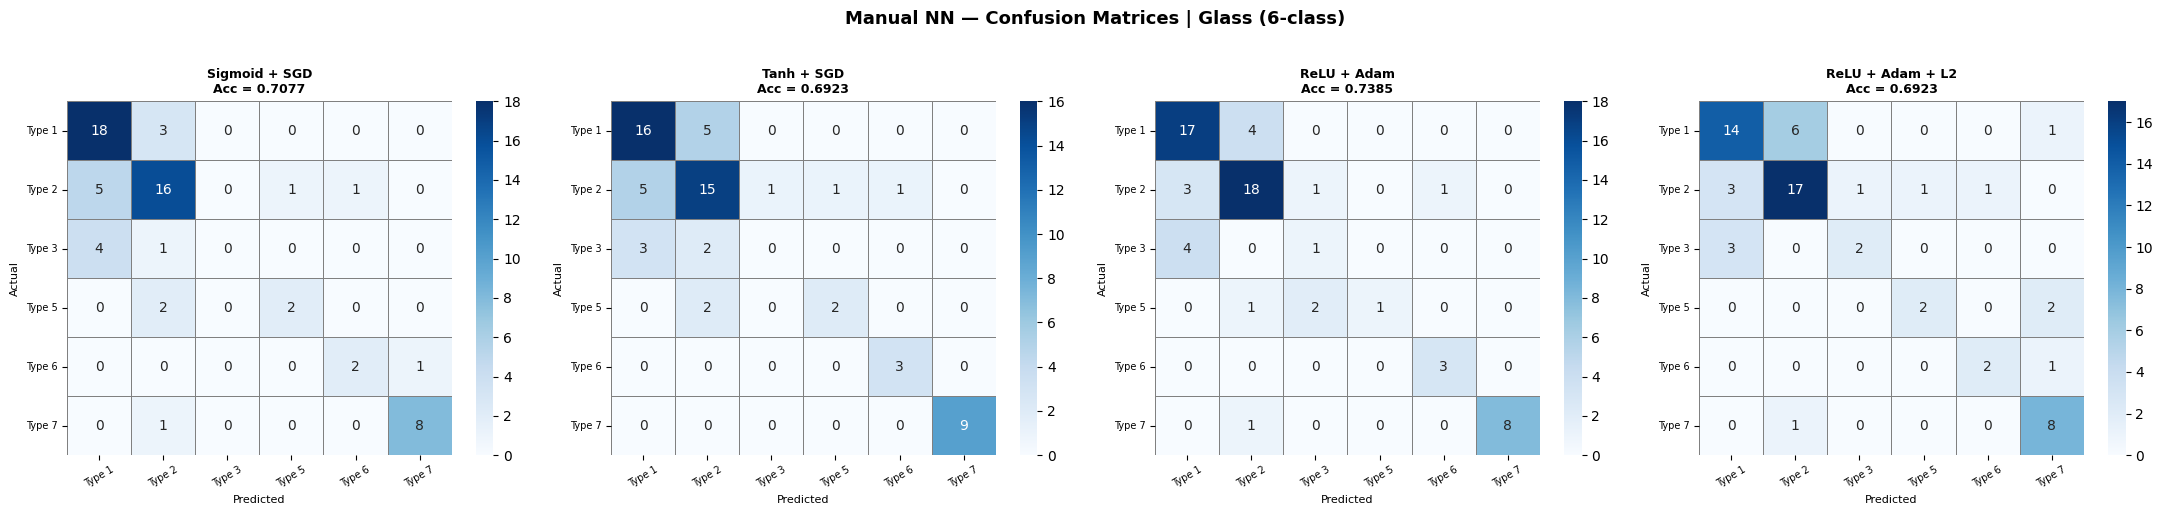

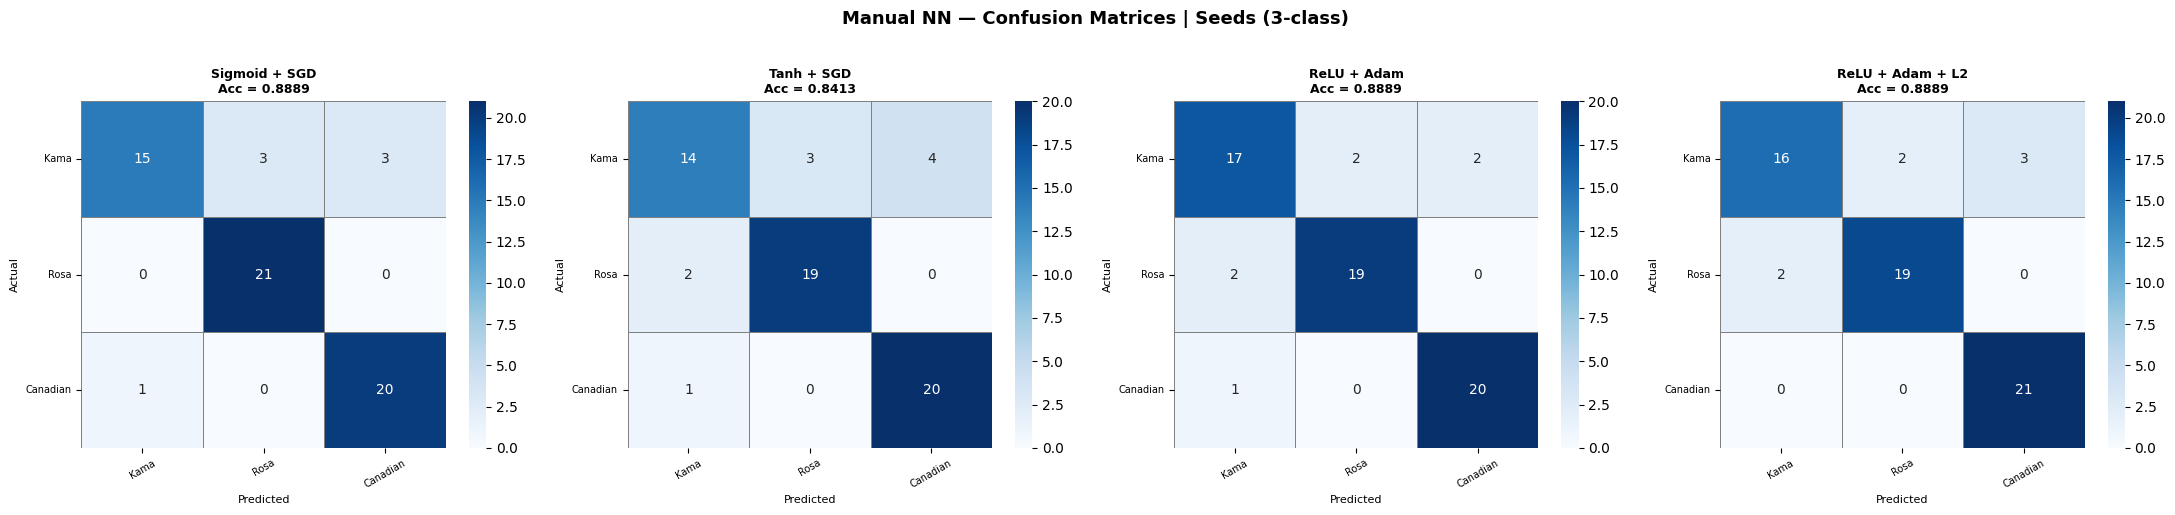

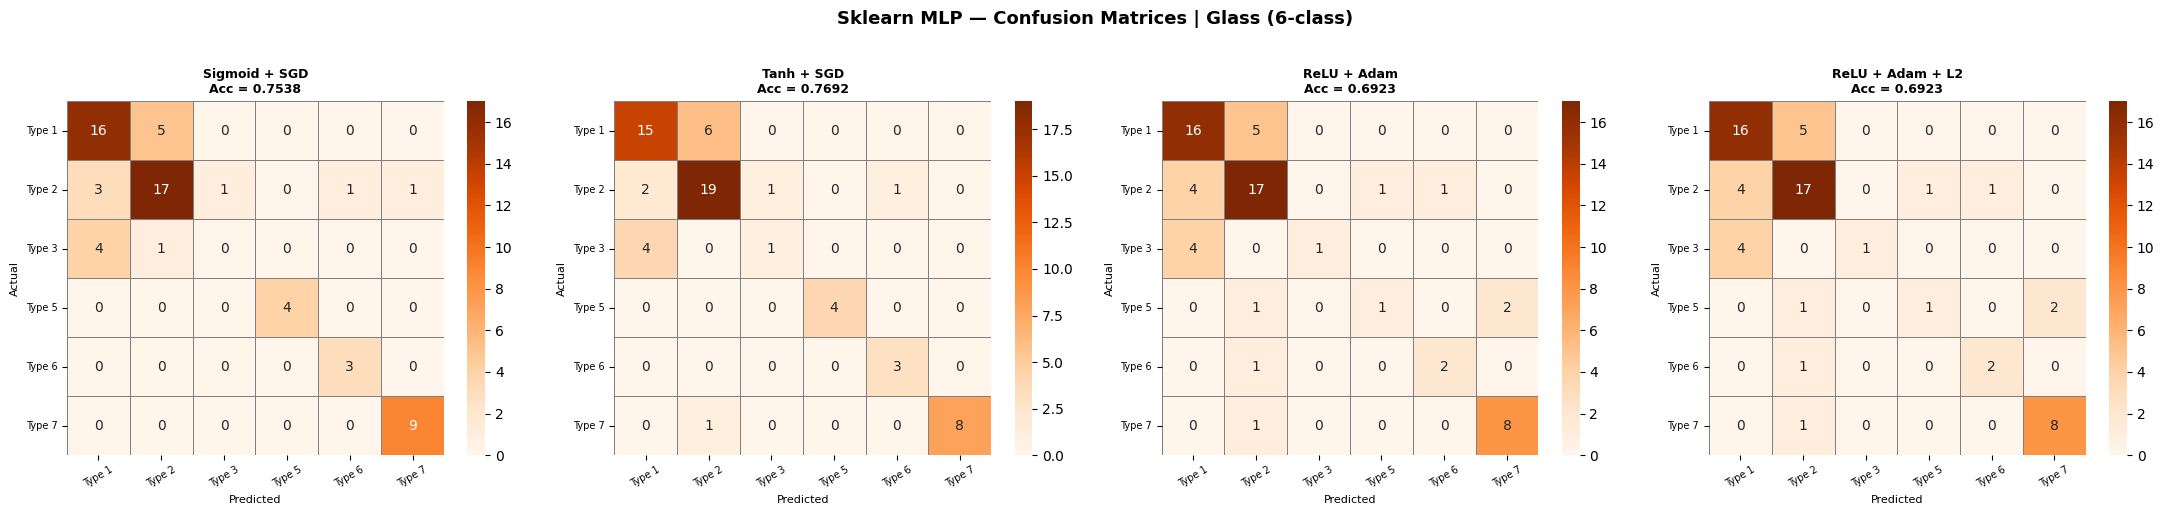

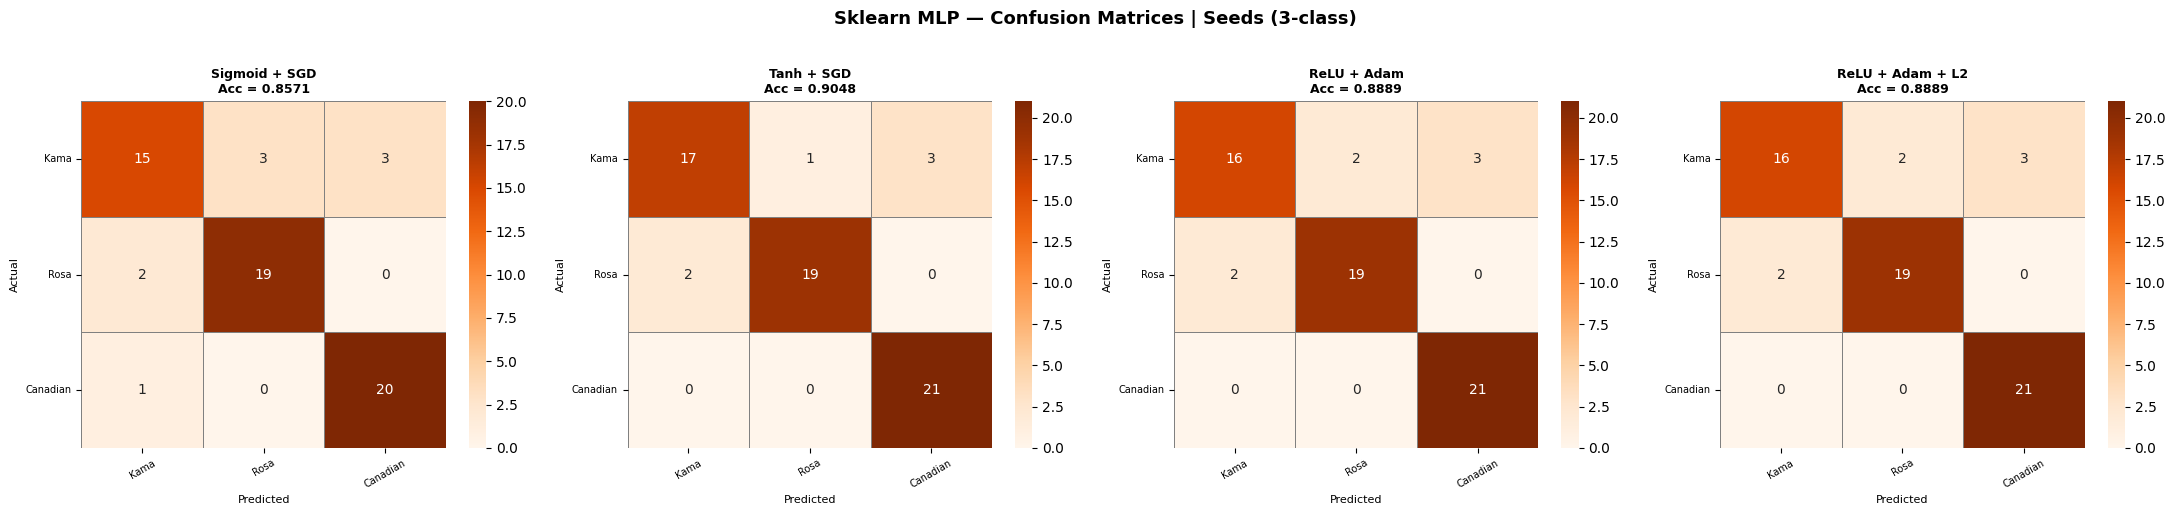

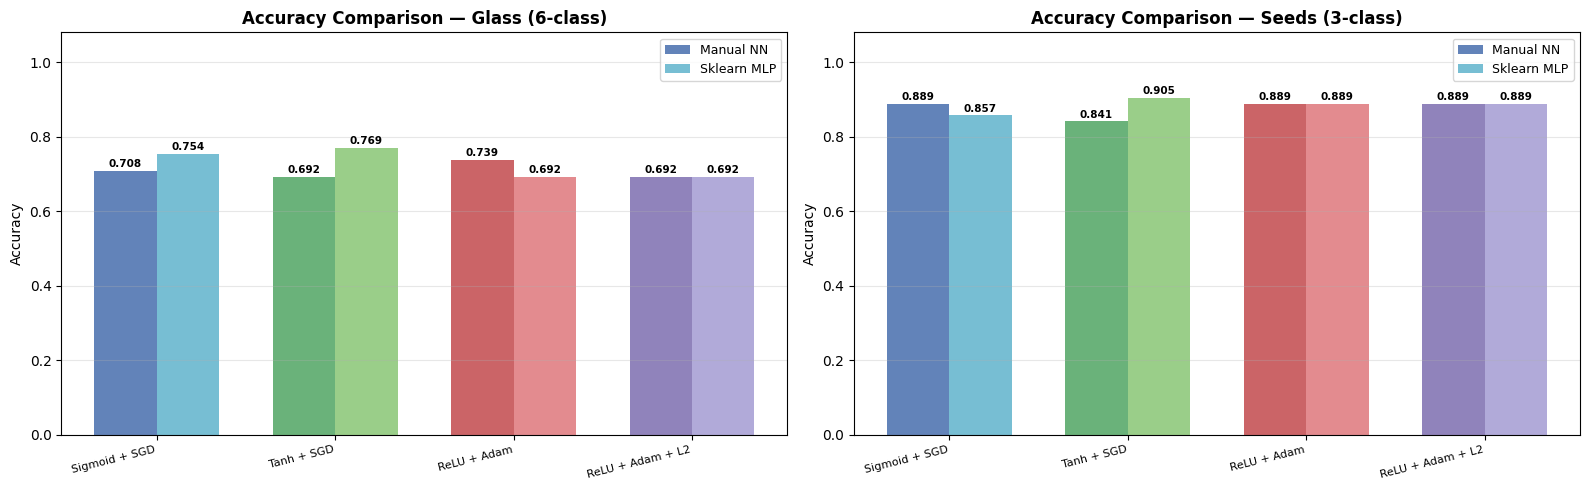

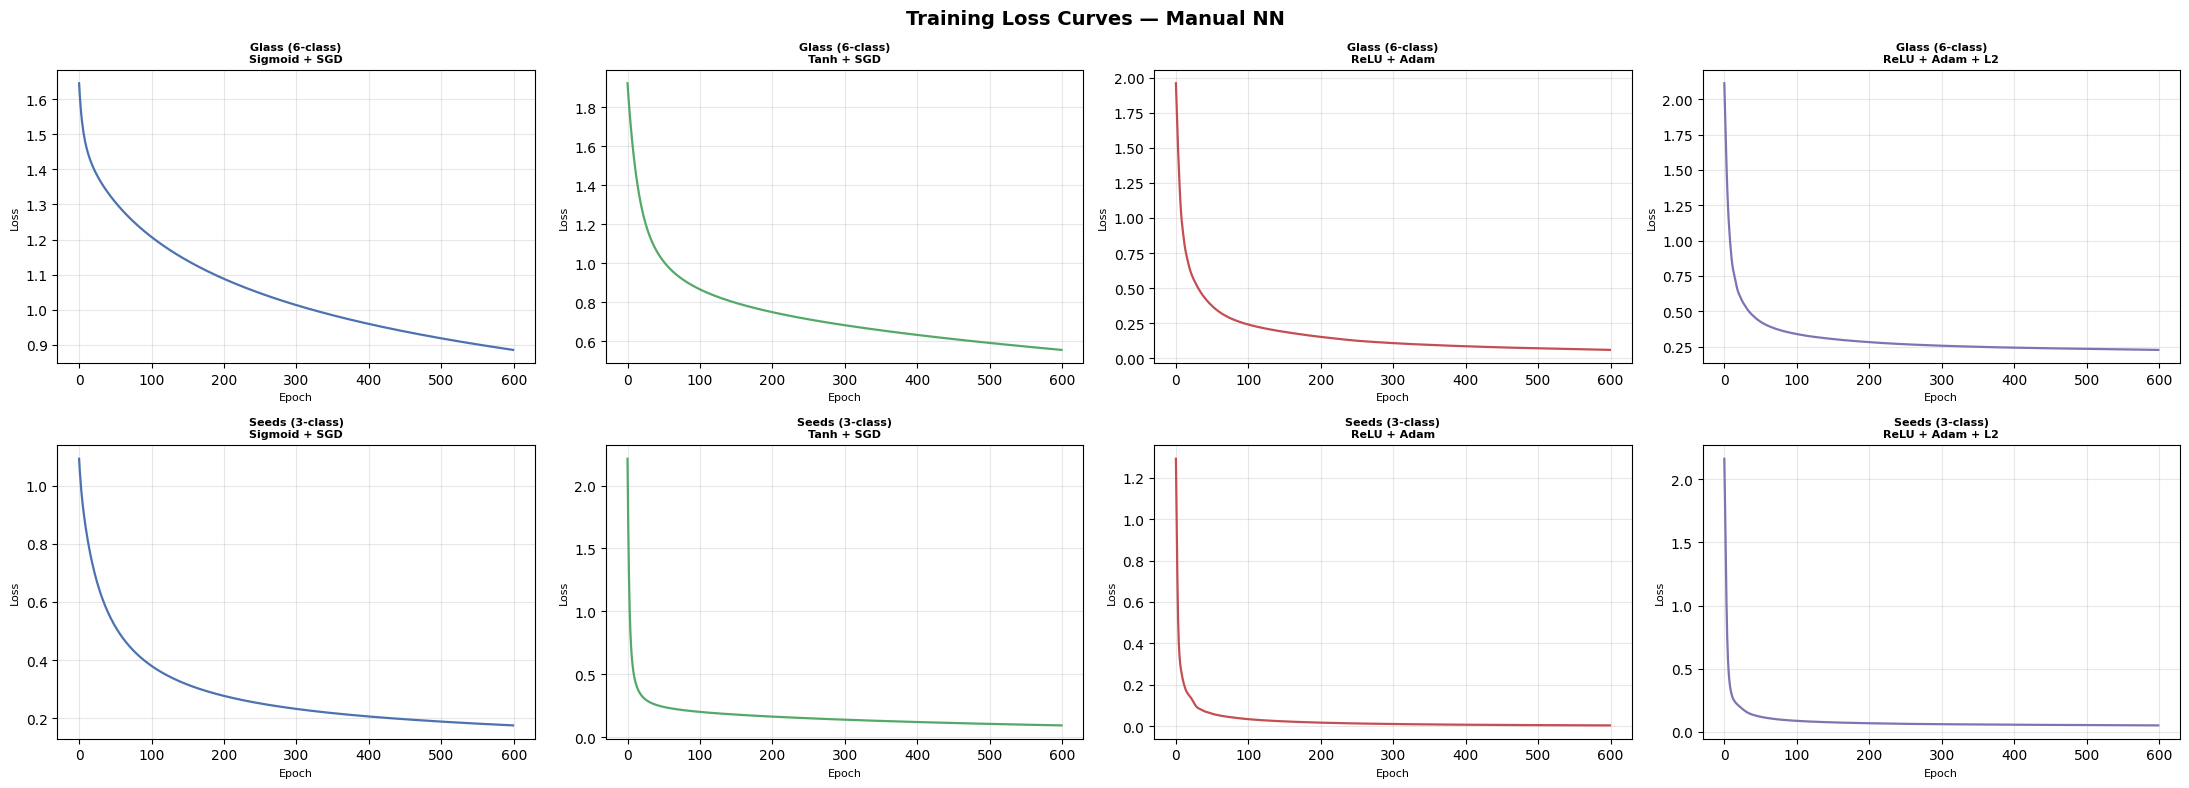

In [ ]:
!pip install scikit-learn pandas numpy matplotlib seaborn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("✓ Libraries loaded.\n")

# ================================================================
# SECTION 1 — DOWNLOAD & PREPARE DATASETS
# ================================================================
print("=" * 65)
print("DOWNLOADING DATASETS")
print("=" * 65)

glass_url = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
             "/glass/glass.data")
glass_cols = ['Id', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
glass_df = pd.read_csv(glass_url, header=None, names=glass_cols)

# Drop Id column; re-encode labels 0-based (original: 1,2,3,5,6,7)
X_glass = glass_df.drop(['Id', 'Type'], axis=1).values
le_glass = LabelEncoder()
y_glass = le_glass.fit_transform(glass_df['Type'].values)   # 0-5
glass_class_names = [f"Type {c}" for c in le_glass.classes_]
n_glass_classes = len(glass_class_names)

print(f"Glass Identification — shape: {glass_df.shape}")
print(f"  Classes ({n_glass_classes}): {le_glass.classes_.tolist()}")

seeds_url = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
             "/00236/seeds_dataset.txt")
seeds_cols = ['Area', 'Perimeter', 'Compactness', 'KernelLength',
              'KernelWidth', 'AsymCoeff', 'GrooveLength', 'Variety']
seeds_df = pd.read_csv(seeds_url, sep=r'\s+', header=None, names=seeds_cols)

X_seeds = seeds_df.iloc[:, :-1].values
le_seeds = LabelEncoder()
y_seeds = le_seeds.fit_transform(seeds_df['Variety'].values)   # 0-2
seeds_class_names = ['Kama', 'Rosa', 'Canadian']
n_seeds_classes = 3

print(f"\nWheat Seeds — shape: {seeds_df.shape}")
print(f"  Classes ({n_seeds_classes}): Kama, Rosa, Canadian")

# ----------------------------------------------------------------
# Helper: split + scale + one-hot
# ----------------------------------------------------------------
def preprocess(X, y, n_classes, test_size=0.3):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y)
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s = sc.transform(X_te)
    y_tr_oh = np.eye(n_classes)[y_tr.astype(int)]
    y_te_oh = np.eye(n_classes)[y_te.astype(int)]
    return X_tr_s, X_te_s, y_tr, y_te, y_tr_oh, y_te_oh

(X_g_tr, X_g_te, y_g_tr, y_g_te,
 y_g_tr_oh, y_g_te_oh) = preprocess(X_glass, y_glass, n_glass_classes)

(X_s_tr, X_s_te, y_s_tr, y_s_te,
 y_s_tr_oh, y_s_te_oh) = preprocess(X_seeds, y_seeds, n_seeds_classes)

print(f"\nGlass   — Train: {X_g_tr.shape[0]}  Test: {X_g_te.shape[0]}")
print(f"Seeds   — Train: {X_s_tr.shape[0]}  Test: {X_s_te.shape[0]}")

# ================================================================
# SECTION 2 — MANUAL NEURAL NETWORK
#   Single hidden layer | Adam optimizer | L2 regularization
# ================================================================

class ManualNN:
    """
    One hidden layer neural network with manual backpropagation.
    Supports:
      Activations : sigmoid, tanh, relu
      Optimizers  : sgd, adam
      Regularizer : L2 (lambda_reg)
    """

    def __init__(self, input_size, hidden_size, output_size,
                 activation='relu', optimizer='adam',
                 lr=0.01, lambda_reg=0.0, epochs=600):
        self.act_type   = activation
        self.optimizer  = optimizer
        self.lr         = lr
        self.lambda_reg = lambda_reg
        self.epochs     = epochs
        self.losses     = []

        # Xavier weight initialisation
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

        # Adam moment buffers
        self.mW1 = np.zeros_like(self.W1); self.vW1 = np.zeros_like(self.W1)
        self.mb1 = np.zeros_like(self.b1); self.vb1 = np.zeros_like(self.b1)
        self.mW2 = np.zeros_like(self.W2); self.vW2 = np.zeros_like(self.W2)
        self.mb2 = np.zeros_like(self.b2); self.vb2 = np.zeros_like(self.b2)
        self.beta1, self.beta2, self.eps = 0.9, 0.999, 1e-8
        self.t = 0

    # ---- Activation functions ----
    def _act(self, z):
        if self.act_type == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        elif self.act_type == 'tanh':
            return np.tanh(z)
        else:                                   # relu
            return np.maximum(0, z)

    def _act_d(self, z):
        if self.act_type == 'sigmoid':
            s = self._act(z); return s * (1 - s)
        elif self.act_type == 'tanh':
            return 1 - np.tanh(z) ** 2
        else:
            return (z > 0).astype(float)

    def _softmax(self, z):
        e = np.exp(z - np.max(z, axis=1, keepdims=True))
        return e / e.sum(axis=1, keepdims=True)

    # ---- Forward pass ----
    def _forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = self._act(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = self._softmax(self.z2)
        return self.a2

    # ---- Adam single-param update ----
    def _adam(self, param, grad, m, v):
        self.t += 1
        m = self.beta1 * m + (1 - self.beta1) * grad
        v = self.beta2 * v + (1 - self.beta2) * grad ** 2
        m_h = m / (1 - self.beta1 ** self.t)
        v_h = v / (1 - self.beta2 ** self.t)
        param -= self.lr * m_h / (np.sqrt(v_h) + self.eps)
        return param, m, v

    # ---- Backward pass ----
    def _backward(self, X, y_oh, out):
        m = X.shape[0]

        # Output-layer gradients
        dz2 = out - y_oh
        dW2 = (self.a1.T @ dz2) / m + self.lambda_reg * self.W2
        db2 = dz2.sum(axis=0, keepdims=True) / m

        # Hidden-layer gradients
        dz1 = (dz2 @ self.W2.T) * self._act_d(self.z1)
        dW1 = (X.T @ dz1) / m + self.lambda_reg * self.W1
        db1 = dz1.sum(axis=0, keepdims=True) / m

        if self.optimizer == 'adam':
            self.t = 0                          # reset per epoch
            self.W2, self.mW2, self.vW2 = self._adam(self.W2, dW2, self.mW2, self.vW2)
            self.b2, self.mb2, self.vb2 = self._adam(self.b2, db2, self.mb2, self.vb2)
            self.W1, self.mW1, self.vW1 = self._adam(self.W1, dW1, self.mW1, self.vW1)
            self.b1, self.mb1, self.vb1 = self._adam(self.b1, db1, self.mb1, self.vb1)
        else:                                   # sgd
            self.W2 -= self.lr * dW2; self.b2 -= self.lr * db2
            self.W1 -= self.lr * dW1; self.b1 -= self.lr * db1

    # ---- Training loop ----
    def fit(self, X, y_oh):
        for _ in range(self.epochs):
            out  = self._forward(X)
            # Cross-entropy + L2 penalty
            ce   = -np.mean(np.log(out[range(len(y_oh)), y_oh.argmax(1)] + 1e-8))
            l2   = (self.lambda_reg / 2) * (np.sum(self.W1**2) + np.sum(self.W2**2))
            self.losses.append(ce + l2)
            self._backward(X, y_oh, out)

    def predict(self, X):
        return np.argmax(self._forward(X), axis=1)

    def score(self, X, y_oh):
        return np.mean(self.predict(X) == y_oh.argmax(1))

# ================================================================
# SECTION 3 — EXPERIMENT SETTINGS
# ================================================================

SETTINGS = [
    {
        'name'   : 'Sigmoid + SGD',
        'tag'    : 'S1',
        'manual' : dict(activation='sigmoid', optimizer='sgd',  lr=0.05, lambda_reg=0.0),
        'sklearn': dict(activation='logistic', solver='sgd',    learning_rate_init=0.05, alpha=0.0)
    },
    {
        'name'   : 'Tanh + SGD',
        'tag'    : 'S2',
        'manual' : dict(activation='tanh',    optimizer='sgd',  lr=0.05, lambda_reg=0.0),
        'sklearn': dict(activation='tanh',    solver='sgd',     learning_rate_init=0.05, alpha=0.0)
    },
    {
        'name'   : 'ReLU + Adam',
        'tag'    : 'S3',
        'manual' : dict(activation='relu',    optimizer='adam', lr=0.01, lambda_reg=0.0),
        'sklearn': dict(activation='relu',    solver='adam',    learning_rate_init=0.01, alpha=0.0)
    },
    {
        'name'   : 'ReLU + Adam + L2',
        'tag'    : 'S4',
        'manual' : dict(activation='relu',    optimizer='adam', lr=0.01, lambda_reg=0.001),
        'sklearn': dict(activation='relu',    solver='adam',    learning_rate_init=0.01, alpha=0.001)
    },
]

EPOCHS = 600
HIDDEN = 40         # hidden neurons

DATASETS = {
    'Glass (6-class)': {
        'X_tr': X_g_tr, 'X_te': X_g_te,
        'y_tr': y_g_tr, 'y_te': y_g_te,
        'y_tr_oh': y_g_tr_oh, 'y_te_oh': y_g_te_oh,
        'n_out': n_glass_classes,
        'labels': glass_class_names
    },
    'Seeds (3-class)': {
        'X_tr': X_s_tr, 'X_te': X_s_te,
        'y_tr': y_s_tr, 'y_te': y_s_te,
        'y_tr_oh': y_s_tr_oh, 'y_te_oh': y_s_te_oh,
        'n_out': n_seeds_classes,
        'labels': seeds_class_names
    }
}

# ================================================================
# SECTION 4 — RUN ALL EXPERIMENTS
# ================================================================

print("\n" + "=" * 65)
print("RUNNING EXPERIMENTS  (4 settings × 2 datasets × Manual + Sklearn)")
print("=" * 65)

all_results = []

for ds_name, ds in DATASETS.items():
    print(f"\n{'─'*65}")
    print(f"  DATASET : {ds_name}")
    print(f"{'─'*65}")

    for s in SETTINGS:
        print(f"  [{s['tag']}] {s['name']} ... ", end='', flush=True)

        # ---- Manual NN ----
        nn = ManualNN(
            input_size  = ds['X_tr'].shape[1],
            hidden_size = HIDDEN,
            output_size = ds['n_out'],
            epochs      = EPOCHS,
            **s['manual']
        )
        nn.fit(ds['X_tr'], ds['y_tr_oh'])
        m_pred = nn.predict(ds['X_te'])
        m_acc  = accuracy_score(ds['y_te'], m_pred)
        m_cm   = confusion_matrix(ds['y_te'], m_pred)

        # ---- Sklearn MLP ----
        mlp = MLPClassifier(
            hidden_layer_sizes = (HIDDEN,),
            max_iter           = EPOCHS,
            random_state       = 42,
            **s['sklearn']
        )
        mlp.fit(ds['X_tr'], ds['y_tr'])
        sk_pred = mlp.predict(ds['X_te'])
        sk_acc  = accuracy_score(ds['y_te'], sk_pred)
        sk_cm   = confusion_matrix(ds['y_te'], sk_pred)

        print(f"Manual={m_acc:.4f}  Sklearn={sk_acc:.4f}")

        all_results.append({
            'Dataset'  : ds_name,
            'Setting'  : s['name'],
            'Tag'      : s['tag'],
            'Manual'   : round(m_acc, 4),
            'Sklearn'  : round(sk_acc, 4),
            'm_cm'     : m_cm,
            'sk_cm'    : sk_cm,
            'labels'   : ds['labels'],
            'losses'   : nn.losses
        })

# ================================================================
# SECTION 5 — ACCURACY SUMMARY TABLE
# ================================================================

print("\n\n" + "=" * 65)
print("ACCURACY SUMMARY TABLE")
print("=" * 65)
summary = pd.DataFrame([{
    'Dataset' : r['Dataset'],
    'Setting' : r['Setting'],
    'Manual Acc' : r['Manual'],
    'Sklearn Acc': r['Sklearn']
} for r in all_results])
print(summary.to_string(index=False))

# ================================================================
# SECTION 6 — CONFUSION MATRICES : MANUAL NN
# ================================================================

for ds_name in DATASETS:
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Manual NN — Confusion Matrices | {ds_name}',
                 fontsize=13, fontweight='bold', y=1.02)
    for ax, r in zip(axes, ds_res):
        sns.heatmap(r['m_cm'], annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=r['labels'], yticklabels=r['labels'],
                    linewidths=0.5, linecolor='grey')
        ax.set_title(f"{r['Setting']}\nAcc = {r['Manual']:.4f}",
                     fontsize=9, fontweight='bold')
        ax.set_xlabel('Predicted', fontsize=8)
        ax.set_ylabel('Actual',    fontsize=8)
        ax.tick_params(axis='x', labelsize=7, rotation=30)
        ax.tick_params(axis='y', labelsize=7, rotation=0)
    plt.tight_layout()
    plt.show()

# ================================================================
# SECTION 7 — CONFUSION MATRICES : SKLEARN MLP
# ================================================================

for ds_name in DATASETS:
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Sklearn MLP — Confusion Matrices | {ds_name}',
                 fontsize=13, fontweight='bold', y=1.02)
    for ax, r in zip(axes, ds_res):
        sns.heatmap(r['sk_cm'], annot=True, fmt='d', cmap='Oranges', ax=ax,
                    xticklabels=r['labels'], yticklabels=r['labels'],
                    linewidths=0.5, linecolor='grey')
        ax.set_title(f"{r['Setting']}\nAcc = {r['Sklearn']:.4f}",
                     fontsize=9, fontweight='bold')
        ax.set_xlabel('Predicted', fontsize=8)
        ax.set_ylabel('Actual',    fontsize=8)
        ax.tick_params(axis='x', labelsize=7, rotation=30)
        ax.tick_params(axis='y', labelsize=7, rotation=0)
    plt.tight_layout()
    plt.show()

# ================================================================
# SECTION 8 — ACCURACY BAR CHART (Manual vs Sklearn, per dataset)
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors_m  = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']
colors_sk = ['#64B5CD', '#8CC879', '#E07B80', '#A79ED4']

for ax, ds_name in zip(axes, DATASETS):
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    tags   = [r['Tag'] for r in ds_res]
    m_acc  = [r['Manual']  for r in ds_res]
    sk_acc = [r['Sklearn'] for r in ds_res]
    x = np.arange(len(tags))
    w = 0.35
    bars_m  = ax.bar(x - w/2, m_acc,  w, label='Manual NN', color=colors_m,  alpha=0.88)
    bars_sk = ax.bar(x + w/2, sk_acc, w, label='Sklearn MLP', color=colors_sk, alpha=0.88)
    ax.set_xticks(x)
    ax.set_xticklabels([r['Setting'] for r in ds_res], rotation=14, ha='right', fontsize=8)
    ax.set_ylabel('Accuracy', fontsize=10)
    ax.set_title(f'Accuracy Comparison — {ds_name}', fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_ylim([0, 1.08])
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars_m,  m_acc):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.3f}', ha='center', fontsize=7.5, fontweight='bold')
    for bar, val in zip(bars_sk, sk_acc):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.3f}', ha='center', fontsize=7.5, fontweight='bold')

plt.tight_layout()
plt.show()

# ================================================================
# SECTION 9 — TRAINING LOSS CURVES (Manual NN, all settings)
# ================================================================

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
fig.suptitle('Training Loss Curves — Manual NN', fontsize=14, fontweight='bold')
palette = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for row_idx, ds_name in enumerate(DATASETS):
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    for col_idx, r in enumerate(ds_res):
        ax = axes[row_idx][col_idx]
        ax.plot(r['losses'], color=palette[col_idx], linewidth=1.6)
        ax.set_title(f"{ds_name}\n{r['Setting']}", fontsize=8, fontweight='bold')
        ax.set_xlabel('Epoch', fontsize=8)
        ax.set_ylabel('Loss',  fontsize=8)
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

✓ Libraries loaded.

DOWNLOADING DATASETS
Glass Identification — shape: (214, 11)
  Classes (6): [1, 2, 3, 5, 6, 7]

Wheat Seeds — shape: (210, 8)
  Classes (3): Kama, Rosa, Canadian

Cross-validation: 5-fold Stratified K-Fold (shuffle=True, random_state=42)
Glass  — total: 214 samples  (~171 train / ~42 test per fold)
Seeds  — total: 210 samples  (~168 train / ~42 test per fold)

RUNNING 5-FOLD CV  (4 settings × 2 datasets × Manual + Sklearn)

─────────────────────────────────────────────────────────────────
  DATASET : Glass (6-class)
─────────────────────────────────────────────────────────────────
  [S1] Sigmoid + SGD ...
       Manual  CV Acc: 0.6587 ± 0.0446  | per-fold: [0.6047, 0.6512, 0.6977, 0.7209, 0.619]
       Sklearn CV Acc: 0.7152 ± 0.0548  | per-fold: [0.6744, 0.7442, 0.6279, 0.7674, 0.7619]
  [S2] Tanh + SGD ...
       Manual  CV Acc: 0.6732 ± 0.0535  | per-fold: [0.5814, 0.6977, 0.6512, 0.6977, 0.7381]
       Sklearn CV Acc: 0.7009 ± 0.0453  | per-fold: [0.7209, 0.697

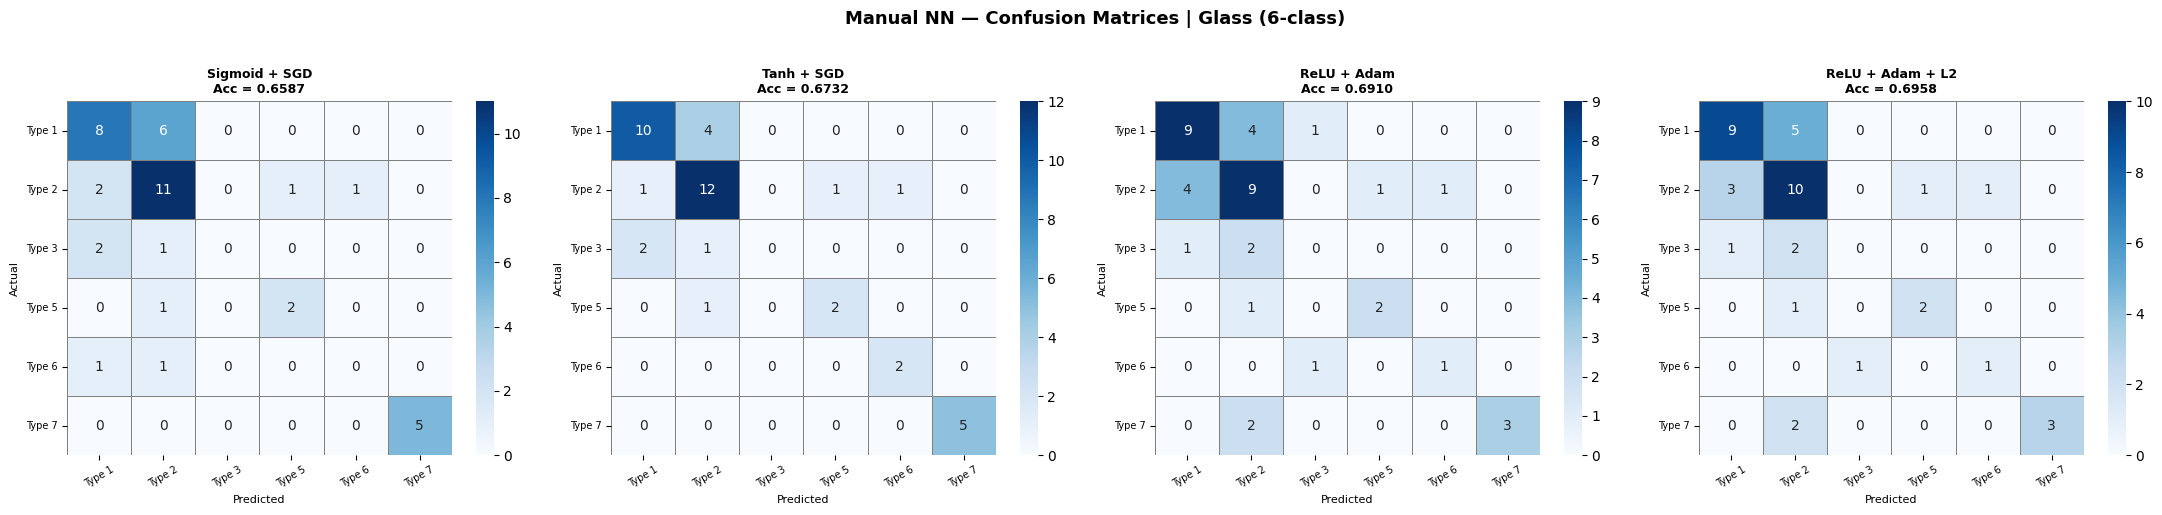

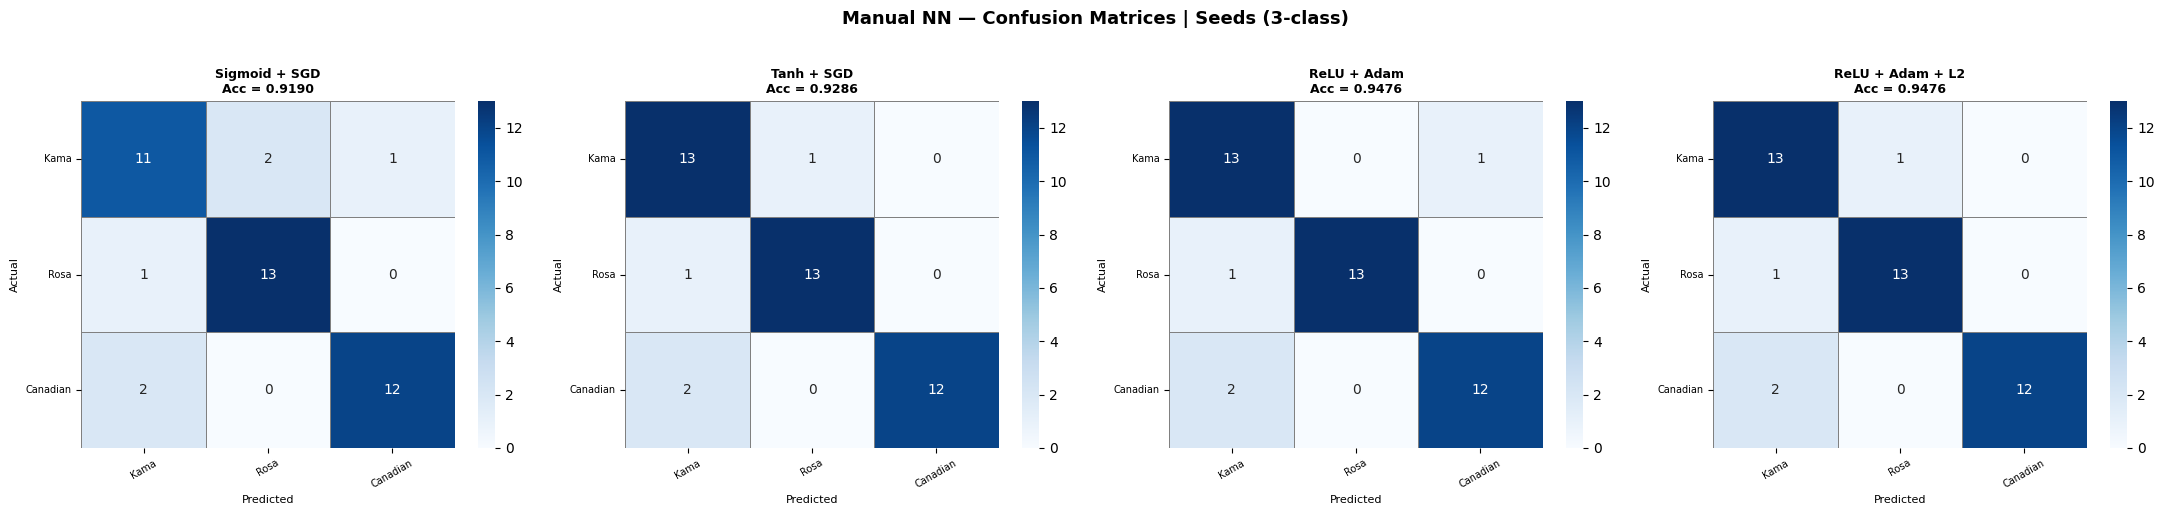

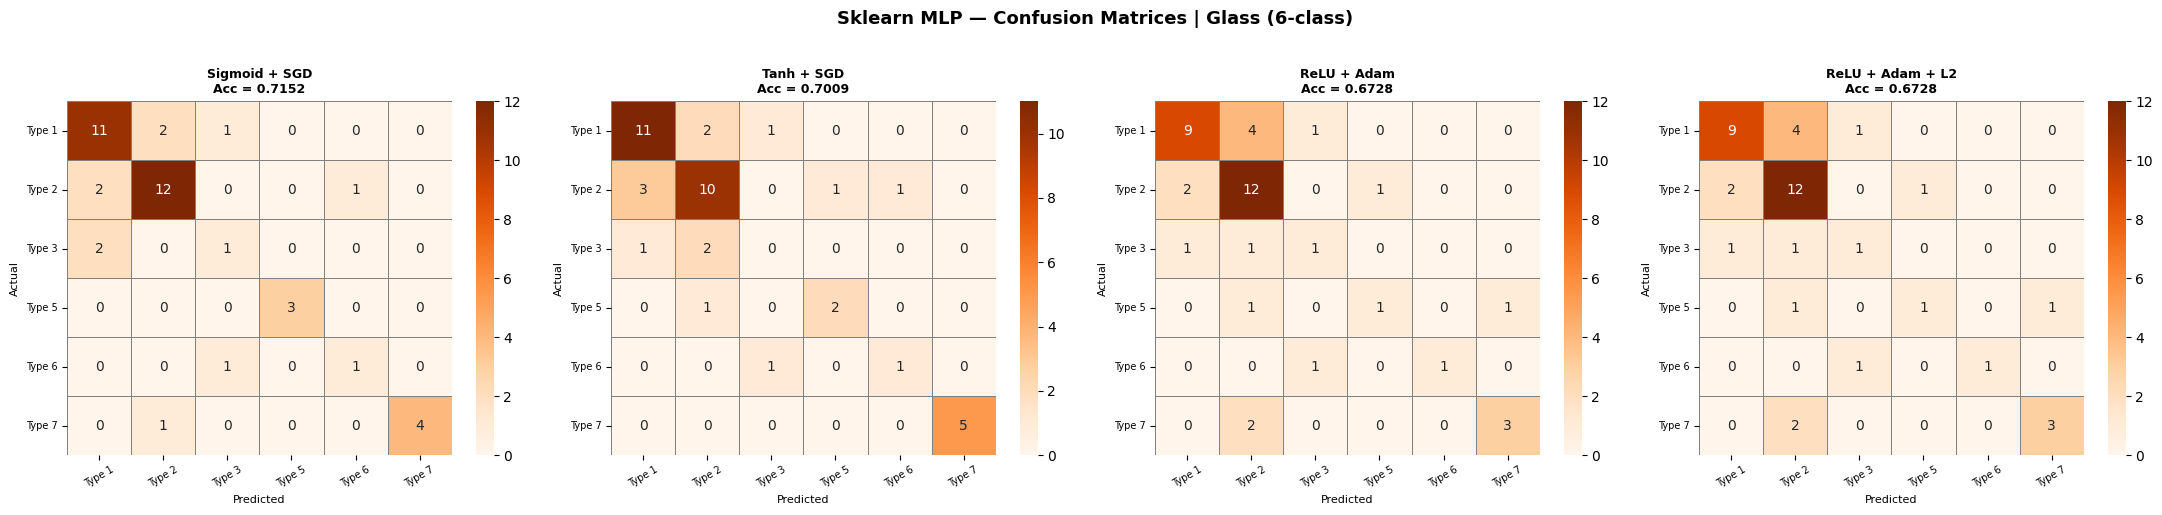

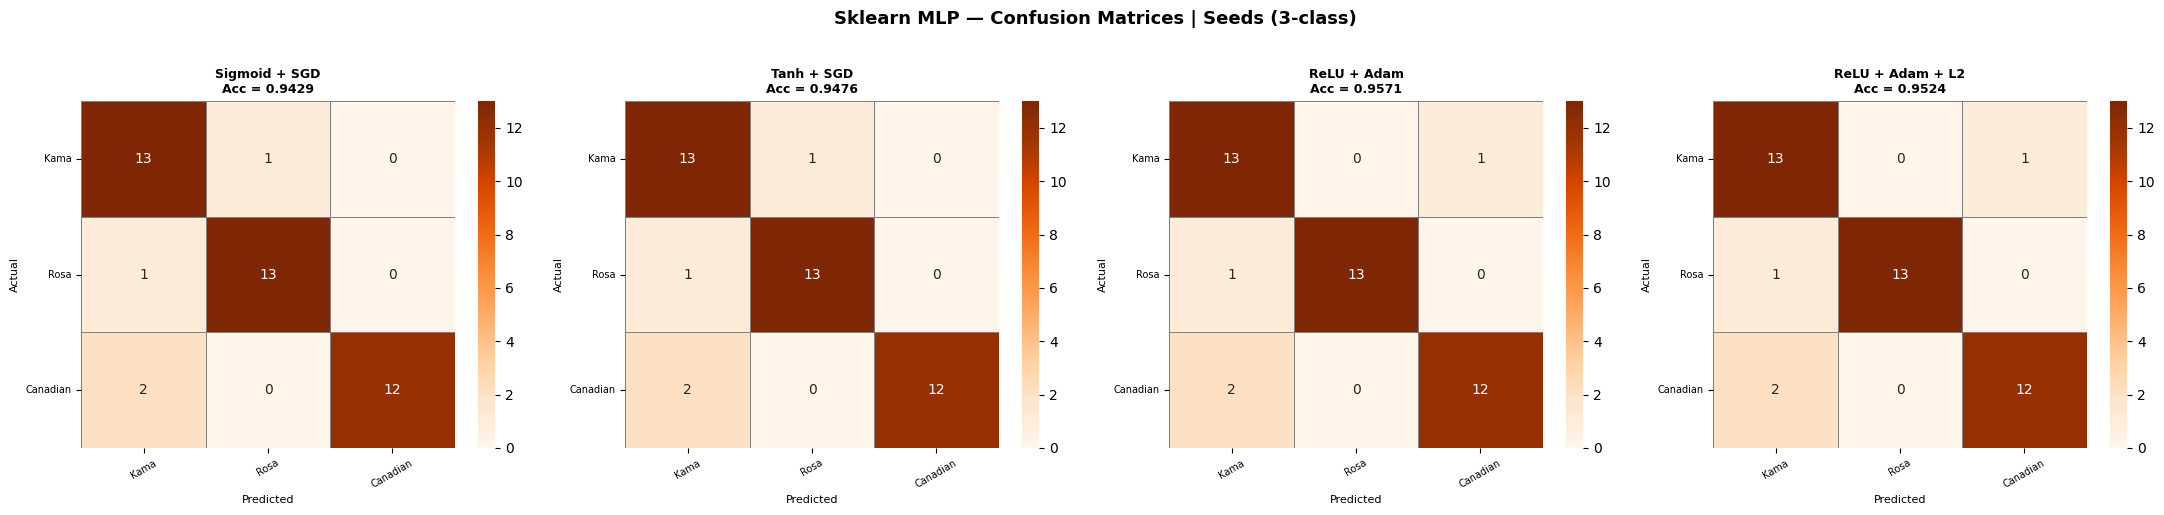

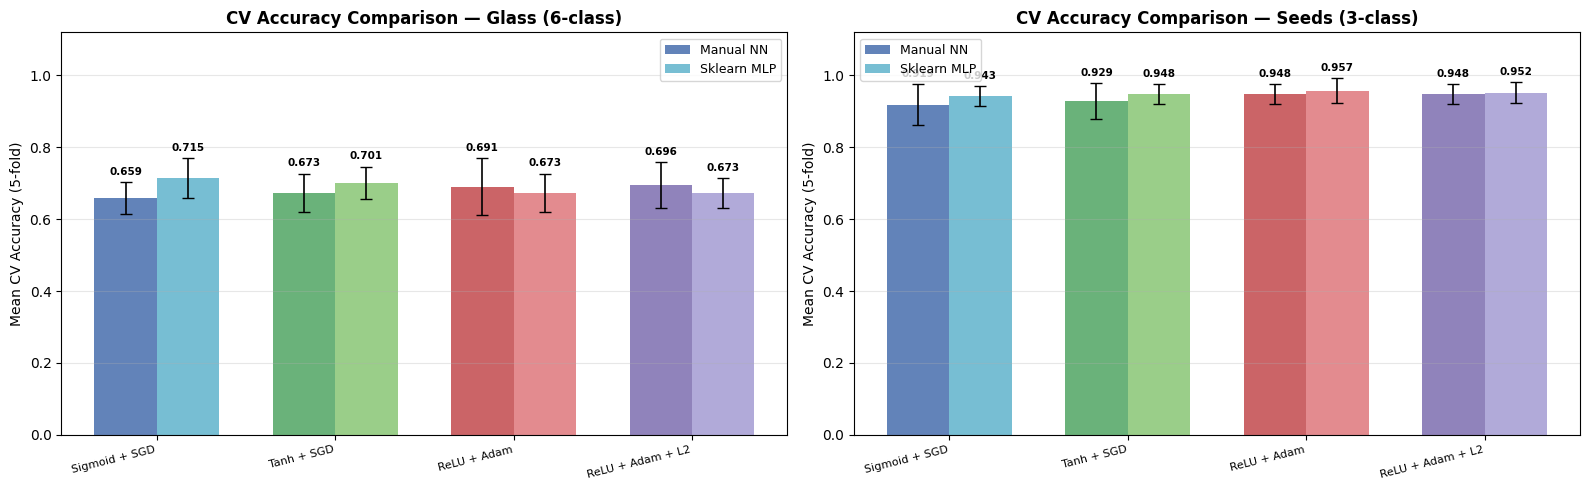

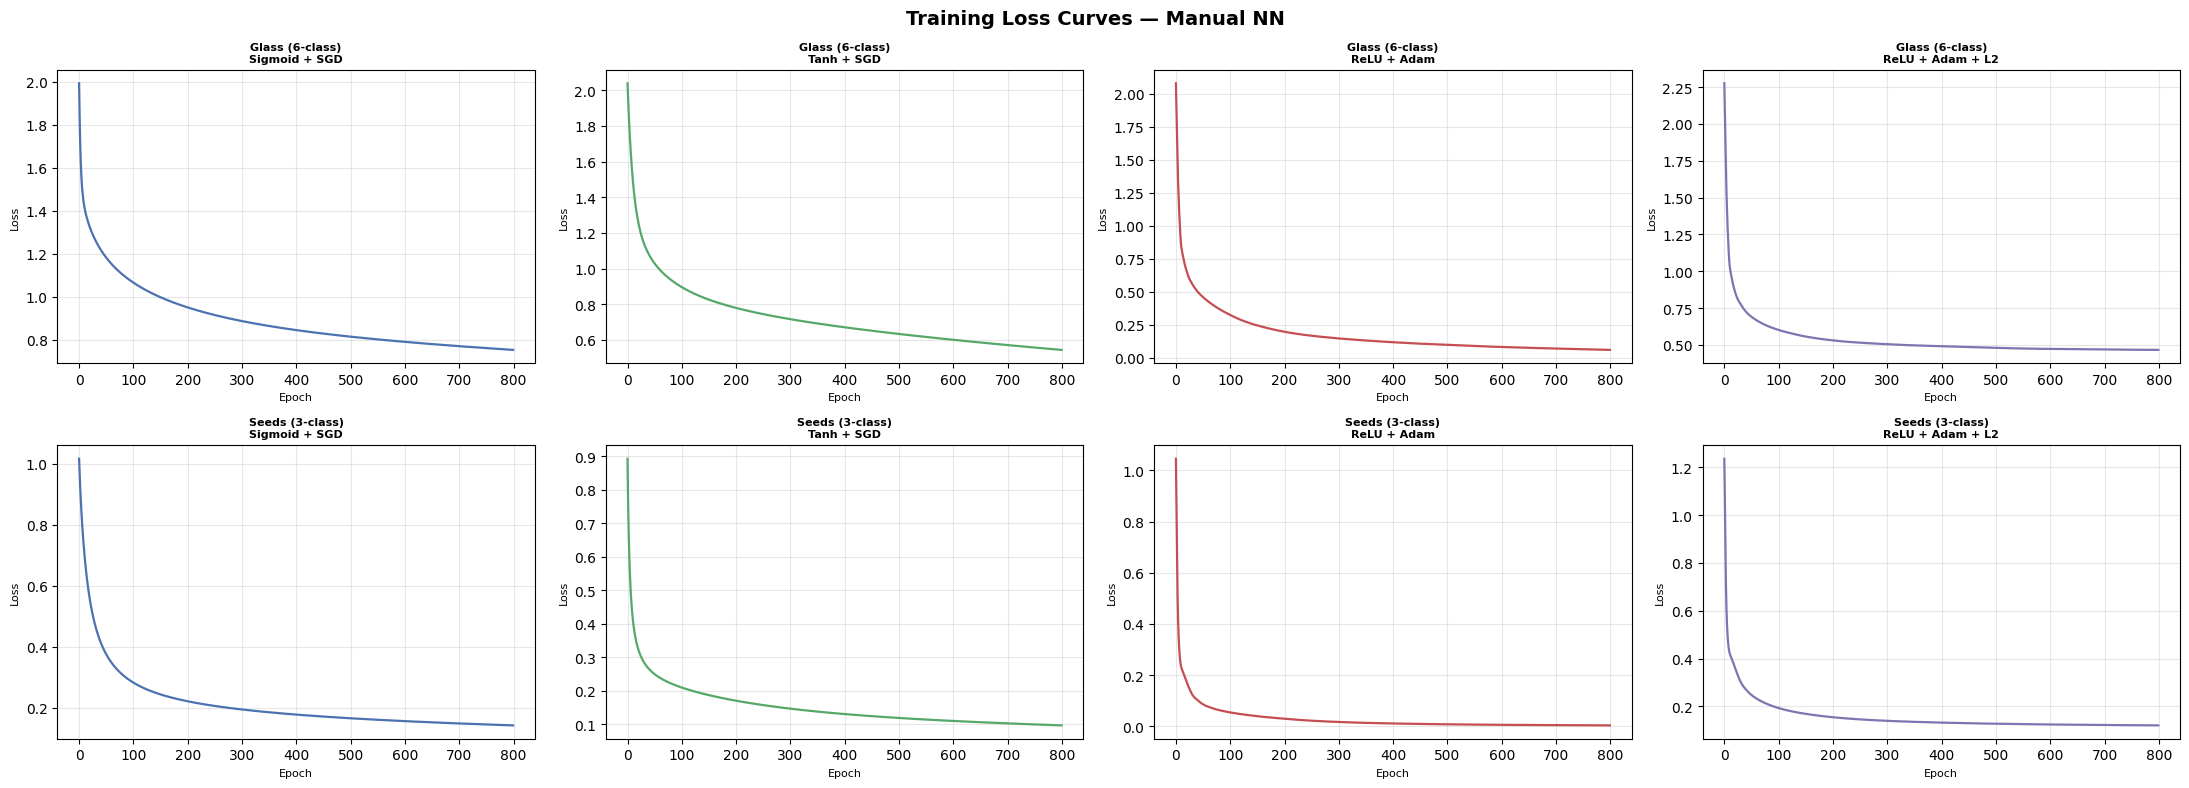

In [ ]:
!pip install scikit-learn pandas numpy matplotlib seaborn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

np.random.seed(7)
print("✓ Libraries loaded.\n")

# ================================================================
# SECTION 1 — DOWNLOAD & PREPARE DATASETS
# ================================================================
print("=" * 65)
print("DOWNLOADING DATASETS")
print("=" * 65)

# ----------------------------------------------------------------
# Dataset 1: Glass Identification
# 214 samples | 9 features | 6 classes
# Classes: 1=building_float, 2=building_non_float, 3=vehicle_float,
#          5=vehicle_non_float, 6=containers, 7=tableware, (no class 4)
# ----------------------------------------------------------------
glass_url = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
             "/glass/glass.data")
glass_cols = ['Id', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
glass_df = pd.read_csv(glass_url, header=None, names=glass_cols)

# Drop Id column; re-encode labels 0-based (original: 1,2,3,5,6,7)
X_glass = glass_df.drop(['Id', 'Type'], axis=1).values
le_glass = LabelEncoder()
y_glass = le_glass.fit_transform(glass_df['Type'].values)   # 0-5
glass_class_names = [f"Type {c}" for c in le_glass.classes_]
n_glass_classes = len(glass_class_names)

print(f"Glass Identification — shape: {glass_df.shape}")
print(f"  Classes ({n_glass_classes}): {le_glass.classes_.tolist()}")

# ----------------------------------------------------------------
# Dataset 2: Wheat Seeds
# 210 samples | 7 features | 3 classes (1=Kama, 2=Rosa, 3=Canadian)
# ----------------------------------------------------------------
seeds_url = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
             "/00236/seeds_dataset.txt")
seeds_cols = ['Area', 'Perimeter', 'Compactness', 'KernelLength',
              'KernelWidth', 'AsymCoeff', 'GrooveLength', 'Variety']
seeds_df = pd.read_csv(seeds_url, sep=r'\s+', header=None, names=seeds_cols)

X_seeds = seeds_df.iloc[:, :-1].values
le_seeds = LabelEncoder()
y_seeds = le_seeds.fit_transform(seeds_df['Variety'].values)   # 0-2
seeds_class_names = ['Kama', 'Rosa', 'Canadian']
n_seeds_classes = 3

print(f"\nWheat Seeds — shape: {seeds_df.shape}")
print(f"  Classes ({n_seeds_classes}): Kama, Rosa, Canadian")

# ----------------------------------------------------------------
# Cross-validation config: 5-fold stratified
# Scaler is fit inside each fold to prevent data leakage
# ----------------------------------------------------------------
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

print(f"\nCross-validation: {N_FOLDS}-fold Stratified K-Fold (shuffle=True, random_state=42)")
print(f"Glass  — total: {X_glass.shape[0]} samples  (~{int(X_glass.shape[0]*0.8)} train / ~{int(X_glass.shape[0]*0.2)} test per fold)")
print(f"Seeds  — total: {X_seeds.shape[0]} samples  (~{int(X_seeds.shape[0]*0.8)} train / ~{int(X_seeds.shape[0]*0.2)} test per fold)")

# ================================================================
# SECTION 2 — MANUAL NEURAL NETWORK
#   Single hidden layer | Adam optimizer | L2 regularization
# ================================================================

class ManualNN:
    """
    One hidden layer neural network with manual backpropagation.
    Supports:
      Activations : sigmoid, tanh, relu
      Optimizers  : sgd, adam
      Regularizer : L2 (lambda_reg)
    """

    def __init__(self, input_size, hidden_size, output_size,
                 activation='relu', optimizer='adam',
                 lr=0.01, lambda_reg=0.0, epochs=600):
        self.act_type   = activation
        self.optimizer  = optimizer
        self.lr         = lr
        self.lambda_reg = lambda_reg
        self.epochs     = epochs
        self.losses     = []

        # Xavier weight initialisation
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

        # Adam moment buffers
        self.mW1 = np.zeros_like(self.W1); self.vW1 = np.zeros_like(self.W1)
        self.mb1 = np.zeros_like(self.b1); self.vb1 = np.zeros_like(self.b1)
        self.mW2 = np.zeros_like(self.W2); self.vW2 = np.zeros_like(self.W2)
        self.mb2 = np.zeros_like(self.b2); self.vb2 = np.zeros_like(self.b2)
        self.beta1, self.beta2, self.eps = 0.9, 0.999, 1e-8
        self.t = 0

    # ---- Activation functions ----
    def _act(self, z):
        if self.act_type == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        elif self.act_type == 'tanh':
            return np.tanh(z)
        else:                                   # relu
            return np.maximum(0, z)

    def _act_d(self, z):
        if self.act_type == 'sigmoid':
            s = self._act(z); return s * (1 - s)
        elif self.act_type == 'tanh':
            return 1 - np.tanh(z) ** 2
        else:
            return (z > 0).astype(float)

    def _softmax(self, z):
        e = np.exp(z - np.max(z, axis=1, keepdims=True))
        return e / e.sum(axis=1, keepdims=True)

    # ---- Forward pass ----
    def _forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = self._act(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = self._softmax(self.z2)
        return self.a2

    # ---- Adam single-param update ----
    def _adam(self, param, grad, m, v):
        self.t += 1
        m = self.beta1 * m + (1 - self.beta1) * grad
        v = self.beta2 * v + (1 - self.beta2) * grad ** 2
        m_h = m / (1 - self.beta1 ** self.t)
        v_h = v / (1 - self.beta2 ** self.t)
        param -= self.lr * m_h / (np.sqrt(v_h) + self.eps)
        return param, m, v

    # ---- Backward pass ----
    def _backward(self, X, y_oh, out):
        m = X.shape[0]

        # Output-layer gradients
        dz2 = out - y_oh
        dW2 = (self.a1.T @ dz2) / m + self.lambda_reg * self.W2
        db2 = dz2.sum(axis=0, keepdims=True) / m

        # Hidden-layer gradients
        dz1 = (dz2 @ self.W2.T) * self._act_d(self.z1)
        dW1 = (X.T @ dz1) / m + self.lambda_reg * self.W1
        db1 = dz1.sum(axis=0, keepdims=True) / m

        if self.optimizer == 'adam':
            self.t = 0                          # reset per epoch
            self.W2, self.mW2, self.vW2 = self._adam(self.W2, dW2, self.mW2, self.vW2)
            self.b2, self.mb2, self.vb2 = self._adam(self.b2, db2, self.mb2, self.vb2)
            self.W1, self.mW1, self.vW1 = self._adam(self.W1, dW1, self.mW1, self.vW1)
            self.b1, self.mb1, self.vb1 = self._adam(self.b1, db1, self.mb1, self.vb1)
        else:                                   # sgd
            self.W2 -= self.lr * dW2; self.b2 -= self.lr * db2
            self.W1 -= self.lr * dW1; self.b1 -= self.lr * db1

    # ---- Training loop ----
    def fit(self, X, y_oh):
        for _ in range(self.epochs):
            out  = self._forward(X)
            # Cross-entropy + L2 penalty
            ce   = -np.mean(np.log(out[range(len(y_oh)), y_oh.argmax(1)] + 1e-8))
            l2   = (self.lambda_reg / 2) * (np.sum(self.W1**2) + np.sum(self.W2**2))
            self.losses.append(ce + l2)
            self._backward(X, y_oh, out)

    def predict(self, X):
        return np.argmax(self._forward(X), axis=1)

    def score(self, X, y_oh):
        return np.mean(self.predict(X) == y_oh.argmax(1))

# ================================================================
# SECTION 3 — EXPERIMENT SETTINGS
# ================================================================

SETTINGS = [
    {
        'name'   : 'Sigmoid + SGD',
        'tag'    : 'S1',
        'manual' : dict(activation='sigmoid', optimizer='sgd',  lr=0.1,  lambda_reg=0.0),
        'sklearn': dict(activation='logistic', solver='sgd',    learning_rate_init=0.1,  alpha=0.0)
    },
    {
        'name'   : 'Tanh + SGD',
        'tag'    : 'S2',
        'manual' : dict(activation='tanh',    optimizer='sgd',  lr=0.05, lambda_reg=0.0),
        'sklearn': dict(activation='tanh',    solver='sgd',     learning_rate_init=0.05, alpha=0.0)
    },
    {
        'name'   : 'ReLU + Adam',
        'tag'    : 'S3',
        'manual' : dict(activation='relu',    optimizer='adam', lr=0.01, lambda_reg=0.0),
        'sklearn': dict(activation='relu',    solver='adam',    learning_rate_init=0.01, alpha=0.0)
    },
    {
        'name'   : 'ReLU + Adam + L2',
        'tag'    : 'S4',
        'manual' : dict(activation='relu',    optimizer='adam', lr=0.01, lambda_reg=0.005),
        'sklearn': dict(activation='relu',    solver='adam',    learning_rate_init=0.01, alpha=0.005)
    },
]

EPOCHS = 800
HIDDEN = 32         # hidden neurons

DATASETS = {
    'Glass (6-class)': {
        'X': X_glass, 'y': y_glass,
        'n_out': n_glass_classes,
        'labels': glass_class_names
    },
    'Seeds (3-class)': {
        'X': X_seeds, 'y': y_seeds,
        'n_out': n_seeds_classes,
        'labels': seeds_class_names
    }
}

# ================================================================
# SECTION 4 — RUN ALL EXPERIMENTS (5-Fold Cross-Validation)
# Each fold: different random 80% train / 20% test split
# Scaler fit on train fold only → no data leakage
# ================================================================

print("\n" + "=" * 65)
print("RUNNING 5-FOLD CV  (4 settings × 2 datasets × Manual + Sklearn)")
print("=" * 65)

all_results = []   # mean accuracy across folds + last-fold CM + last-fold losses

for ds_name, ds in DATASETS.items():
    X_all = ds['X']
    y_all = ds['y']
    n_out = ds['n_out']

    print(f"\n{'─'*65}")
    print(f"  DATASET : {ds_name}")
    print(f"{'─'*65}")

    for s in SETTINGS:
        print(f"  [{s['tag']}] {s['name']} ...", flush=True)

        fold_m_accs  = []
        fold_sk_accs = []
        last_m_cm = last_sk_cm = last_losses = None

        for fold_idx, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all)):
            # ---- Split this fold ----
            X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
            y_tr_raw, y_te_raw = y_all[tr_idx], y_all[te_idx]

            # ---- Scale inside fold (no leakage) ----
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr_raw)
            X_te = sc.transform(X_te_raw)

            # One-hot for manual NN
            y_tr_oh = np.eye(n_out)[y_tr_raw.astype(int)]
            y_te_oh = np.eye(n_out)[y_te_raw.astype(int)]

            # ---- Manual NN ----
            np.random.seed(fold_idx * 13 + 3)   # different init each fold
            nn = ManualNN(
                input_size  = X_tr.shape[1],
                hidden_size = HIDDEN,
                output_size = n_out,
                epochs      = EPOCHS,
                **s['manual']
            )
            nn.fit(X_tr, y_tr_oh)
            m_pred = nn.predict(X_te)
            fold_m_accs.append(accuracy_score(y_te_raw, m_pred))

            # ---- Sklearn MLP ----
            mlp = MLPClassifier(
                hidden_layer_sizes = (HIDDEN,),
                max_iter           = EPOCHS,
                random_state       = fold_idx,
                **s['sklearn']
            )
            mlp.fit(X_tr, y_tr_raw)
            sk_pred = mlp.predict(X_te)
            fold_sk_accs.append(accuracy_score(y_te_raw, sk_pred))

            # Save last fold for confusion matrix and loss curve display
            if fold_idx == N_FOLDS - 1:
                last_m_cm   = confusion_matrix(y_te_raw, m_pred)
                last_sk_cm  = confusion_matrix(y_te_raw, sk_pred)
                last_losses = nn.losses

        mean_m  = round(float(np.mean(fold_m_accs)),  4)
        std_m   = round(float(np.std(fold_m_accs)),   4)
        mean_sk = round(float(np.mean(fold_sk_accs)), 4)
        std_sk  = round(float(np.std(fold_sk_accs)),  4)

        print(f"       Manual  CV Acc: {mean_m:.4f} ± {std_m:.4f}  "
              f"| per-fold: {[round(a,4) for a in fold_m_accs]}")
        print(f"       Sklearn CV Acc: {mean_sk:.4f} ± {std_sk:.4f}  "
              f"| per-fold: {[round(a,4) for a in fold_sk_accs]}")

        all_results.append({
            'Dataset'    : ds_name,
            'Setting'    : s['name'],
            'Tag'        : s['tag'],
            'Manual'     : mean_m,
            'Manual_std' : std_m,
            'Sklearn'    : mean_sk,
            'Sklearn_std': std_sk,
            'm_cm'       : last_m_cm,
            'sk_cm'      : last_sk_cm,
            'labels'     : ds['labels'],
            'losses'     : last_losses
        })

# ================================================================
# SECTION 5 — ACCURACY SUMMARY TABLE  (mean ± std over 5 folds)
# ================================================================

print("\n\n" + "=" * 65)
print("ACCURACY SUMMARY TABLE  (5-Fold CV Mean ± Std)")
print("=" * 65)
summary_rows = []
for r in all_results:
    summary_rows.append({
        'Dataset'        : r['Dataset'],
        'Setting'        : r['Setting'],
        'Manual Acc'     : f"{r['Manual']:.4f} ± {r['Manual_std']:.4f}",
        'Sklearn Acc'    : f"{r['Sklearn']:.4f} ± {r['Sklearn_std']:.4f}",
    })
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

# ================================================================
# SECTION 6 — CONFUSION MATRICES : MANUAL NN
# ================================================================

for ds_name in DATASETS:
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Manual NN — Confusion Matrices | {ds_name}',
                 fontsize=13, fontweight='bold', y=1.02)
    for ax, r in zip(axes, ds_res):
        sns.heatmap(r['m_cm'], annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=r['labels'], yticklabels=r['labels'],
                    linewidths=0.5, linecolor='grey')
        ax.set_title(f"{r['Setting']}\nAcc = {r['Manual']:.4f}",
                     fontsize=9, fontweight='bold')
        ax.set_xlabel('Predicted', fontsize=8)
        ax.set_ylabel('Actual',    fontsize=8)
        ax.tick_params(axis='x', labelsize=7, rotation=30)
        ax.tick_params(axis='y', labelsize=7, rotation=0)
    plt.tight_layout()
    plt.show()

# ================================================================
# SECTION 7 — CONFUSION MATRICES : SKLEARN MLP
# ================================================================

for ds_name in DATASETS:
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Sklearn MLP — Confusion Matrices | {ds_name}',
                 fontsize=13, fontweight='bold', y=1.02)
    for ax, r in zip(axes, ds_res):
        sns.heatmap(r['sk_cm'], annot=True, fmt='d', cmap='Oranges', ax=ax,
                    xticklabels=r['labels'], yticklabels=r['labels'],
                    linewidths=0.5, linecolor='grey')
        ax.set_title(f"{r['Setting']}\nAcc = {r['Sklearn']:.4f}",
                     fontsize=9, fontweight='bold')
        ax.set_xlabel('Predicted', fontsize=8)
        ax.set_ylabel('Actual',    fontsize=8)
        ax.tick_params(axis='x', labelsize=7, rotation=30)
        ax.tick_params(axis='y', labelsize=7, rotation=0)
    plt.tight_layout()
    plt.show()

# ================================================================
# SECTION 8 — ACCURACY BAR CHART (Manual vs Sklearn, per dataset)
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors_m  = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']
colors_sk = ['#64B5CD', '#8CC879', '#E07B80', '#A79ED4']

for ax, ds_name in zip(axes, DATASETS):
    ds_res  = [r for r in all_results if r['Dataset'] == ds_name]
    m_acc   = [r['Manual']      for r in ds_res]
    m_std   = [r['Manual_std']  for r in ds_res]
    sk_acc  = [r['Sklearn']     for r in ds_res]
    sk_std  = [r['Sklearn_std'] for r in ds_res]
    x = np.arange(len(ds_res))
    w = 0.35
    bars_m  = ax.bar(x - w/2, m_acc,  w, label='Manual NN',   color=colors_m,  alpha=0.88,
                     yerr=m_std,  capsize=4, error_kw={'elinewidth':1.2})
    bars_sk = ax.bar(x + w/2, sk_acc, w, label='Sklearn MLP', color=colors_sk, alpha=0.88,
                     yerr=sk_std, capsize=4, error_kw={'elinewidth':1.2})
    ax.set_xticks(x)
    ax.set_xticklabels([r['Setting'] for r in ds_res], rotation=14, ha='right', fontsize=8)
    ax.set_ylabel('Mean CV Accuracy (5-fold)', fontsize=10)
    ax.set_title(f'CV Accuracy Comparison — {ds_name}', fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_ylim([0, 1.12])
    ax.grid(axis='y', alpha=0.3)
    for bar, val, std in zip(bars_m,  m_acc, m_std):
        ax.text(bar.get_x() + bar.get_width()/2, val + std + 0.02,
                f'{val:.3f}', ha='center', fontsize=7.5, fontweight='bold')
    for bar, val, std in zip(bars_sk, sk_acc, sk_std):
        ax.text(bar.get_x() + bar.get_width()/2, val + std + 0.02,
                f'{val:.3f}', ha='center', fontsize=7.5, fontweight='bold')

plt.tight_layout()
plt.show()

# ================================================================
# SECTION 9 — TRAINING LOSS CURVES (Manual NN, all settings)
# ================================================================

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
fig.suptitle('Training Loss Curves — Manual NN', fontsize=14, fontweight='bold')
palette = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for row_idx, ds_name in enumerate(DATASETS):
    ds_res = [r for r in all_results if r['Dataset'] == ds_name]
    for col_idx, r in enumerate(ds_res):
        ax = axes[row_idx][col_idx]
        ax.plot(r['losses'], color=palette[col_idx], linewidth=1.6)
        ax.set_title(f"{ds_name}\n{r['Setting']}", fontsize=8, fontweight='bold')
        ax.set_xlabel('Epoch', fontsize=8)
        ax.set_ylabel('Loss',  fontsize=8)
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

